# Solaris

## Imports

In [41]:
from IPython.display import clear_output, display
from contextlib import contextmanager
from dataclasses import dataclass
import matplotlib.pyplot as plt
import gymnasium as gym
import numpy as np
import ale_py
import pygame
import time

## Helper functions

In [2]:
# See the preprocessing section where these values have been chosen
def trim_frame(frame):
    return frame[2:-13, 8:, :]

## Environment

In [3]:
# I will use context managers for managing the environment to ensure that it will be reset and closed
WINDOW_SIZE = (455, 580)

@contextmanager
def create_env(env_name, live_rendering=False, **kwargs):
    env = gym.make(env_name, **kwargs)
    env.reset()
    env.__setattr__('_live_rendering', live_rendering)

    if live_rendering:
        if env.render_mode != 'rgb_array':
            raise ValueError('Render mode should be rgb_array for live rendering')
        
        pygame.init()
        pygame.display.set_caption(env_name)
        pygame.event.set_allowed([pygame.QUIT, pygame.KEYDOWN])

        env.__setattr__('_clock', pygame.time.Clock())
        env.__setattr__('_screen', pygame.display.set_mode(WINDOW_SIZE, pygame.RESIZABLE))
    try:
        yield env
    finally:
        env.close()

        if live_rendering:
            pygame.quit()

# I will also use a dataclass for episode to keep the loop cleaner
@dataclass
class Episode:
    env: gym.Env
    
    obs: object = None
    reward: float | None = None
    terminated: bool = False
    truncated: bool = False
    info: dict | None = None

    stop_rendering = False

    def _render(self):
        for event in pygame.event.get():
            if event.type == pygame.QUIT:
                self.stop_rendering = True

                return

        screen = self.env.__getattribute__('_screen')
        frame = trim_frame(self.env.render())
        
        raw_surface = pygame.surfarray.make_surface(np.transpose(frame, (1, 0, 2)))
        upscaled_surface = pygame.transform.scale_by(raw_surface, 3)

        scr_w, scr_h = screen.get_size()
        surf_w, surf_h = upscaled_surface.get_size()
        
        x_offset = (scr_w - surf_w) // 2
        y_offset = (scr_h - surf_h) // 2

        screen.fill((0, 0, 0))
        screen.blit(upscaled_surface, (x_offset, y_offset))

        pygame.display.flip()

        self.env.__getattribute__('_clock').tick(60)

    @property
    def done(self):
        return self.terminated or self.truncated or self.stop_rendering
    
    def step(self, action):
        self.obs, self.reward, self.terminated, self.truncated, self.info = self.env.step(action)

        if not self.done and self.env.__getattribute__('_live_rendering'):
            self._render()

@contextmanager
def create_episode(env, **kwargs):
    obs, info = env.reset(**kwargs)

    yield Episode(env, obs=obs, info=info)

In [ ]:
# Testing the live rendering
def test_rendering():
    with create_env('ALE/Solaris-v5', live_rendering=True, render_mode='rgb_array') as env:
        for _ in range(10):
            with create_episode(env) as episode:
                while not episode.done:
                    action = env.action_space.sample()
                    episode.step(action)

                if episode.stop_rendering:
                    break

# test_rendering()

## Preprocessing

Action Space: Discrete(18)
State space: Box(0, 255, (210, 160, 3), uint8)


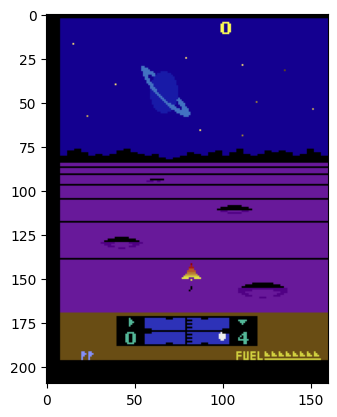

In [5]:
# Let's first check what the input looks like
with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
    print(f'Action Space: {env.action_space}')
    print(f'State space: {env.observation_space}')

    plt.imshow(env.render())

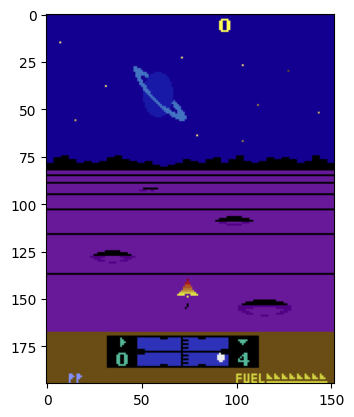

In [6]:
# The game state appears to have some black padding.
# We will trim these pixels.
# The function is defined above so it can be used for live rendering.
with create_env('ALE/Solaris-v5', render_mode='rgb_array') as env:
    plt.imshow(env.render()[2:-13, 8:, :])

In [7]:
# Looking back at the solaris page on the gymnasium website there is an alternative observation space that is just 128 values.
# This is because the Atari 2600 only had 128 bytes of RAM and with this mode the agent has direct access to these values.
with create_env('ALE/Solaris-v5', obs_type='ram') as env:
    print(f'Action Space: {env.action_space}')
    print(f'State space: {env.observation_space}')

Action Space: Discrete(18)
State space: Box(0, 255, (128,), uint8)


In [ ]:
# There is a caveat with this approach and that is that due to the limited RAM the same slots can be used for different things
# depending on the current game state. The usage of the slot for multiple things is not that big of an issue itself since 
# the network can act on this using the game state but for the network to be able to filter the value the game state should be 
# one-hot encoded.

# I found a copy of the source code of the game online (https://forums.atariage.com/topic/64694-original-source-code/).
# Within this I found 2 memory banks presumably for the sector selection and the gameplay itself.
# The RAM addresses within the console start at 0x80 so we will subtract this for the indices of the array.
ADDRESS_OFFSET = 0x80

def display_state(env, ram, clear=True):
    frame = env.render()
    ram_grid = ram.reshape((16, 8))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.imshow(trim_frame(frame))
    ax1.axis('off')

    im = ax2.imshow(ram_grid, cmap='viridis', vmin=0, vmax=255)
    ax2.set_title('RAM State')

    for i in range(16):
        for j in range(8):
            location = i * 8 + j + ADDRESS_OFFSET
            color = 'white' if ram_grid[i, j] < 128 else 'black'

            ax2.text(j, i, hex(location), ha='center', va='center', fontsize=7, color=color, alpha=0.5)
            
    plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

    if clear:
        clear_output(wait=True)
    
    display(plt.gcf())
    plt.close(fig)

    for i in range(16):
        for j in range(8):
            print(f'{hex(i * 8 + j + ADDRESS_OFFSET)}: {ram_grid[i, j]:>3}, ', end='')

        print()

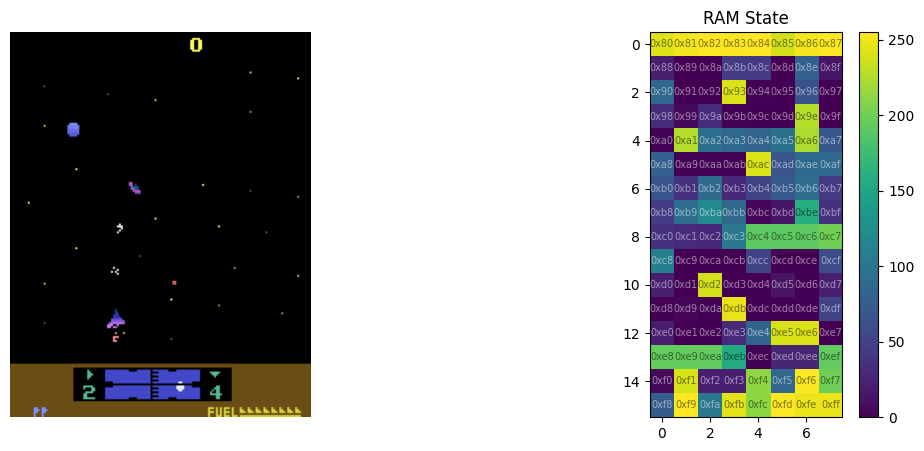

0x80: 243, 0x81: 251, 0x82: 255, 0x83: 254, 0x84: 255, 0x85: 239, 0x86: 251, 0x87: 255, 
0x88:  21, 0x89:   0, 0x8a:   0, 0x8b:  44, 0x8c:  43, 0x8d:   0, 0x8e:  78, 0x8f:  14, 
0x90:  86, 0x91:   0, 0x92:   0, 0x93: 241, 0x94:   1, 0x95:   0, 0x96:  64, 0x97:   0, 
0x98:  32, 0x99:   5, 0x9a:  32, 0x9b:   2, 0x9c:   0, 0x9d:   0, 0x9e: 227, 0x9f:   0, 
0xa0:   1, 0xa1: 226, 0xa2:  92, 0xa3:  86, 0xa4:  81, 0xa5:  94, 0xa6: 224, 0xa7:  69, 
0xa8:  78, 0xa9:   1, 0xaa:   1, 0xab:   1, 0xac: 241, 0xad:  67, 0xae:  87, 0xaf:  87, 
0xb0:  67, 0xb1:  36, 0xb2:  88, 0xb3:  29, 0xb4:  50, 0xb5:  71, 0xb6:  91, 0xb7:  42, 
0xb8:  44, 0xb9:  92, 0xba: 122, 0xbb:  86, 0xbc:   3, 0xbd:  15, 0xbe: 160, 0xbf:  36, 
0xc0:  36, 0xc1:  31, 0xc2:  29, 0xc3: 102, 0xc4: 192, 0xc5: 192, 0xc6: 192, 0xc7: 201, 
0xc8: 110, 0xc9:   0, 0xca:   0, 0xcb:   0, 0xcc:  50, 0xcd:   0, 0xce:   0, 0xcf:  59, 
0xd0:  21, 0xd1:   0, 0xd2: 238, 0xd3:   0, 0xd4:   0, 0xd5:  13, 0xd6:   0, 0xd7:  21, 
0xd8:   0, 0xd9:   3,

In [ ]:
def ram_state_test():
    with create_env('ALE/Solaris-v5', obs_type='ram', render_mode='rgb_array') as env:
        with create_episode(env) as episode:
            while not episode.done:
                action = env.action_space.sample()
                episode.step(action)
                display_state(env, episode.obs)

# ram_state_test()